In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import average_precision_score
from common import (
    TARGET_LABEL, FEATURES, CATEGORICAL, VAL_START, VAL_END, TRAIN_END,
    train_start_for, select_period, load_data, fit_model,
)

CAT_MASK = [True] * len(CATEGORICAL) + [False] * (len(FEATURES) - len(CATEGORICAL))

PARAMS = {"random_state": 42, "learning_rate": 0.1, "max_iter": 500, "max_leaf_nodes": 31,
          "min_samples_leaf": 20, "early_stopping": False, "categorical_features": CAT_MASK}
YEARS = 1
FRACTION = 0.25




In [4]:
df = load_data(YEARS)
train = select_period(df, train_start_for(YEARS), TRAIN_END)
validation = select_period(df, VAL_START, VAL_END)
subset = train.sample(frac=FRACTION, random_state=PARAMS["random_state"]).sort_index()

preprocess = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                            max_categories=254), CATEGORICAL)],
    remainder="passthrough")

model = HistGradientBoostingClassifier(**PARAMS)
pipeline, train_seconds = fit_model(model, subset, preprocess)
print(f"{train_seconds:.1f} s")


26.5 s


In [5]:

model = pipeline.named_steps["model"]
encoder = pipeline.named_steps["preprocess"]

X_train = encoder.transform(subset[FEATURES])
X_val = encoder.transform(validation[FEATURES])
y_train = subset[TARGET_LABEL]
y_val = validation[TARGET_LABEL]

train_stages = model.staged_predict_proba(X_train)
val_stages = model.staged_predict_proba(X_val)

trees = []
val_lifts = []
for i, p_val in enumerate(val_stages, start=1):
    if i % 10 == 0:
        trees.append(i)
        val_lifts.append(average_precision_score(y_val, p_val[:, 1]) / y_val.mean())

train_lifts = []
for i, p_train in enumerate(train_stages, start=1):
    if i % 10 == 0:
        train_lifts.append(average_precision_score(y_train, p_train[:, 1]) / y_train.mean())

Best: 80 tree, validation lift 1.711


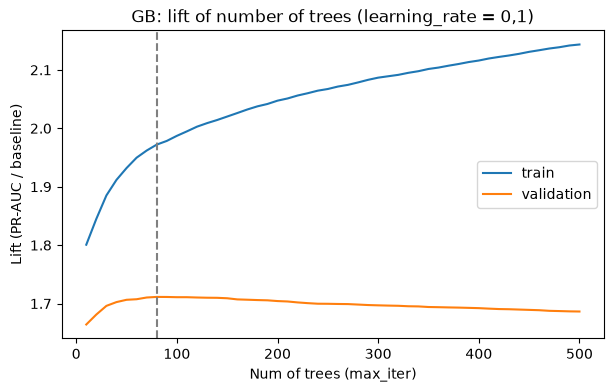

In [ ]:
best = int(np.argmax(val_lifts))
print(f"Best: {trees[best]} tree, validation lift {val_lifts[best]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(trees, train_lifts, label="train")
ax.plot(trees, val_lifts, label="validation")
ax.axvline(trees[best], color="gray", linestyle="--")
ax.set_xlabel("Num of trees (max_iter)")
ax.set_ylabel("Lift (PR-AUC / baseline)")
ax.set_title("GB: lift depending on the number of lifts (learning_rate = 0,1)")
ax.legend()
fig.savefig("../docs/figures/gb_staged_max_iter.png", dpi=150, bbox_inches="tight")